# Лабораторная работа №3. Стационарная теплопроводность 

## 1. Постановка задачи

Найти распределение температуры в квадратном сечении бесконечной балки:
$$u_{xx}+u_{yy}=0,\qquad 0<x<L,\quad 0<y<L,\quad L=0.1\text{ м}.$$
На AB (слева) задано $u=1$, на BC (сверху) — $u=2$,
на CD (справа) — $u=3$, на DA (снизу) — $u=4$.
Точка A находится в левом нижнем углу; $T=100u$ в градусах Цельсия.

Реализуем методы Якоби, Зейделя и верхней релаксации, сравним скорость
сходимости, проверим сгущение сетки и влияние параметра релаксации.
Построим изолинии и сечения $T(x)$ и $T(y)$.
Все методы представлены обычными функциями без классов.

## 2. Библиотеки и параметры

Измените исходные данные ниже и выполните тетрадь сверху вниз.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Edit the physical data and numerical settings here.
length = 0.1
temperature_scale = 100.0
left, top, right, bottom = 1.0, 2.0, 3.0, 4.0
intervals = 20
tolerance = 1e-9
max_iterations = 50000
methods = ["Jacobi", "Gauss-Seidel", "SOR"]

if not np.all(np.isfinite([length, temperature_scale, left, top, right, bottom])):
    raise ValueError("Physical parameters must be finite.")
if length <= 0 or temperature_scale <= 0:
    raise ValueError("Length and temperature scale must be positive.")

## 3. Теория и методы

### Сетка и разностная схема

Используем равномерную сетку с $h_x=h_y=h=L/n$ и пятиузловую схему:
$$u_{j,i}=\frac{u_{j,i-1}+u_{j,i+1}+u_{j-1,i}+u_{j+1,i}}4.$$
В массиве первая координата — номер строки по y, вторая — по x.
Внутри области начальное приближение равно нулю; границы фиксированы.
В углах значения соседних сторон не согласованы: используем их среднее.
Угловые узлы не входят ни в одну схему для внутренних точек.

In [ ]:
def initial_temperature(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 2:
        raise ValueError("The grid needs at least two intervals per side.")
    u = np.zeros((n + 1, n + 1))
    u[1:-1, 0], u[1:-1, -1] = left, right
    u[0, 1:-1], u[-1, 1:-1] = bottom, top
    # Corner averages are a plotting convention, not extra interior equations.
    u[0, 0], u[0, -1] = (bottom + left) / 2, (bottom + right) / 2
    u[-1, 0], u[-1, -1] = (top + left) / 2, (top + right) / 2
    return u

def neighbor_average(u):
    return (u[1:-1, :-2] + u[1:-1, 2:] + u[:-2, 1:-1] + u[2:, 1:-1]) / 4

def residual_norm(u):
    # Divide the discrete Laplace operator by its diagonal coefficient.
    return np.max(np.abs(neighbor_average(u) - u[1:-1, 1:-1]))

### 1. Метод Якоби

Все новые значения вычисляются по предыдущей итерации:
$$u_{j,i}^{(k+1)}=\frac{u_{j,i-1}^{(k)}+u_{j,i+1}^{(k)}
+u_{j-1,i}^{(k)}+u_{j+1,i}^{(k)}}4.$$
NumPy сначала вычисляет правую часть целиком, поэтому присваивание
внутри массива не смешивает старые и новые значения.

In [ ]:
def jacobi_step(u):
    # The array expression is evaluated before the interior is overwritten.
    u[1:-1, 1:-1] = neighbor_average(u)

### 2. Метод Зейделя

Обходим узлы последовательно. Левый и нижний соседи уже обновлены:
$$u_{j,i}^{(k+1)}=\frac{u_{j,i-1}^{(k+1)}+u_{j-1,i}^{(k+1)}
+u_{j,i+1}^{(k)}+u_{j+1,i}^{(k)}}4.$$

In [ ]:
def seidel_step(u):
    for j in range(1, u.shape[0] - 1):
        for i in range(1, u.shape[1] - 1):
            # Updated left/lower values are used immediately.
            u[j, i] = (u[j, i - 1] + u[j, i + 1] + u[j - 1, i] + u[j + 1, i]) / 4

### 3. Метод верхней релаксации (SOR)

Смешиваем старое значение и результат шага Зейделя $\overline u$:
$$u_{j,i}^{(k+1)}=u_{j,i}^{(k)}+\omega(\overline u_{j,i}-u_{j,i}^{(k)}).$$
Здесь $\omega$ соответствует $\tau$ из задания. При $\omega=1$ получаем
метод Зейделя; верхняя релаксация использует $1<\omega<2$.

In [ ]:
def sor_step(u, omega):
    for j in range(1, u.shape[0] - 1):
        for i in range(1, u.shape[1] - 1):
            average = (u[j, i - 1] + u[j, i + 1] + u[j - 1, i] + u[j + 1, i]) / 4
            u[j, i] += omega * (average - u[j, i])

### Общий цикл итераций и теоретическая скорость

Критерий остановки одинаков для трёх методов:
$\|b-Au\|_\infty/\|b\|_\infty\leq tolerance$.
При нулевом начальном приближении знаменатель равен начальной невязке.
Для нулевой правой части используем абсолютную невязку.

На квадратной сетке $\rho_J=\cos(\pi/n)$, $\rho_{GS}=\rho_J^2$.
Оптимальный параметр $\omega_{opt}=2/(1+\sin(\pi/n))$, а
$\rho_{SOR}(\omega_{opt})=\omega_{opt}-1$.
Чем меньше спектральный радиус, тем быстрее асимптотическая сходимость.
При фиксированном уменьшении ошибки Якоби и Зейделю требуется порядка
$O(n^2)$ итераций, оптимальному SOR — порядка $O(n)$.

In [ ]:
def optimal_omega(n):
    return 2 / (1 + np.sin(np.pi / n))

def spectral_radius(n, method, omega=1.0):
    rho = np.cos(np.pi / n)
    if method == "Jacobi":
        return rho
    if method == "Gauss-Seidel":
        return rho**2
    discriminant = omega**2 * rho**2 - 4 * (omega - 1)
    if discriminant <= 0:
        return omega - 1
    return ((omega * rho + np.sqrt(discriminant)) / 2)**2

def solve_heat(n, method, omega=1.0, tol=tolerance, limit=max_iterations):
    if method not in methods:
        raise ValueError("Unknown heat solver method.")
    if not np.isfinite(tol) or not 0 < tol < 1:
        raise ValueError("Tolerance must be between zero and one.")
    if not isinstance(limit, int) or limit < 1:
        raise ValueError("The iteration limit must be a positive integer.")
    if method == "SOR" and (not np.isfinite(omega) or not 1 <= omega < 2):
        raise ValueError("SOR requires 1 <= omega < 2.")
    u = initial_temperature(n)
    scale = residual_norm(u) or 1.0
    history = [residual_norm(u) / scale]
    if history[0] <= tol:
        return u, history
    for _ in range(limit):
        if method == "Jacobi":
            jacobi_step(u)
        elif method == "Gauss-Seidel":
            seidel_step(u)
        else:
            sor_step(u, omega)
        value = residual_norm(u) / scale
        if not np.isfinite(value):
            raise ArithmeticError("The heat equation residual is not finite.")
        history.append(value)
        if value <= tol:
            return u, history
    raise RuntimeError(f"{method} reached the iteration limit.")

## 4. Расчёты и графики

### Сравнение методов

Используем одну сетку, одно начальное приближение и одинаковый допуск.
Сравниваем число итераций, а не время Python-циклов с операциями NumPy.
Для SOR берём теоретически оптимальный параметр.

Method          Iterations   Relative residual   Theoretical rho
Jacobi             1385      9.980e-10          0.987688


Gauss-Seidel        694      9.995e-10          0.975528
SOR                  80      5.519e-10          0.729454


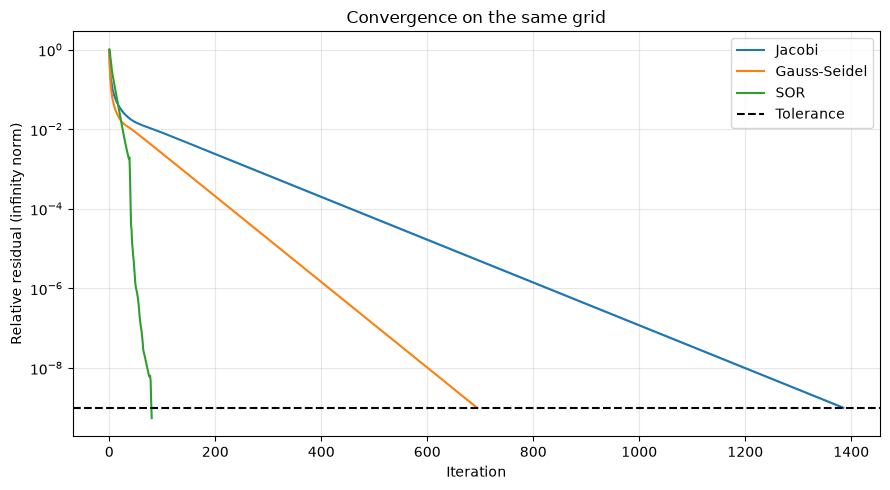

In [ ]:
solutions, histories = {}, {}
omega = optimal_omega(intervals)
print("Method          Iterations   Relative residual   Theoretical rho")
for method in methods:
    u, history = solve_heat(intervals, method, omega)
    solutions[method], histories[method] = u, history
    print(f"{method:14s} {len(history)-1:8d}      {history[-1]:.3e}          "
          f"{spectral_radius(intervals, method, omega):.6f}")

fig, ax = plt.subplots(figsize=(9, 5))
for method in methods:
    values = np.asarray(histories[method])
    ax.semilogy(np.where(values > 0, values, np.nan), label=method)
ax.axhline(tolerance, color="black", linestyle="--", label="Tolerance")
ax.set_xlabel("Iteration")
ax.set_ylabel("Relative residual (infinity norm)")
ax.set_title("Convergence on the same grid")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

### Изолинии и сечения температуры

Решения методов должны совпадать с точностью итерационного допуска.
Для рисунков используем SOR и переводим относительные значения в градусы:
$T=100u$. Сечения выбираются приблизительно на четверти, половине
и трёх четвертях стороны; в легенде указана фактическая координата узла.

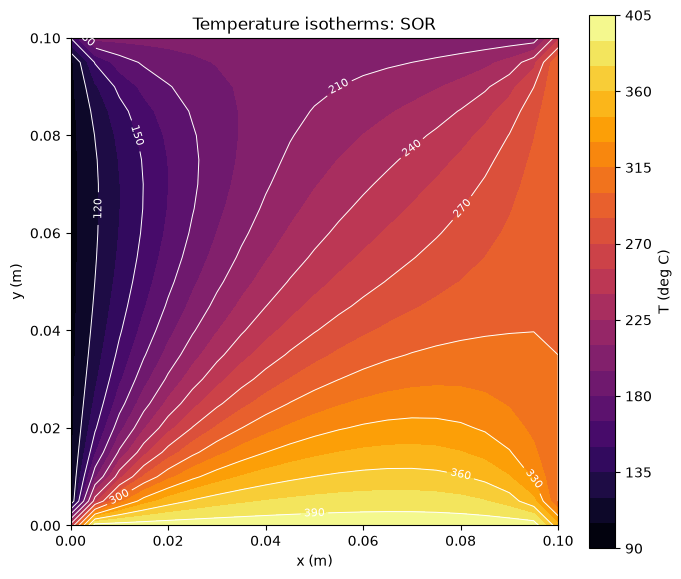

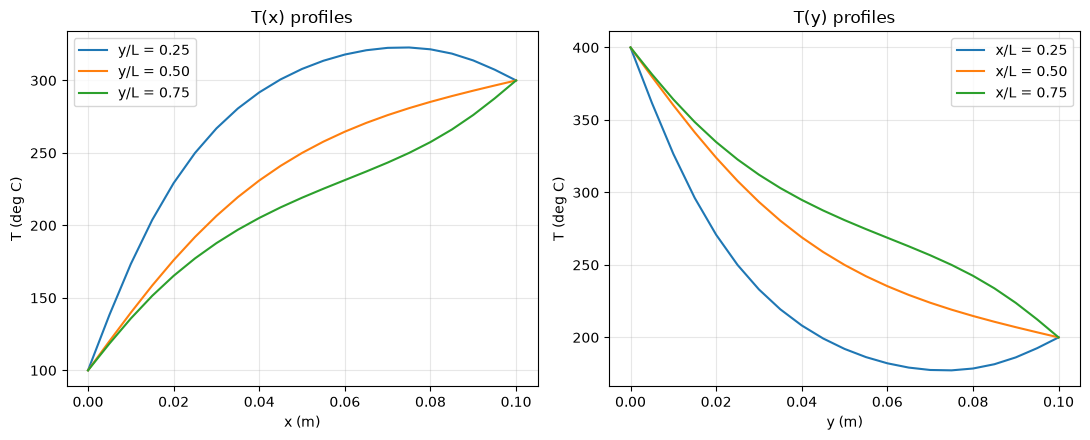

In [ ]:
coordinates = np.linspace(0, length, intervals + 1)
temperature = solutions["SOR"] * temperature_scale
fig, ax = plt.subplots(figsize=(7, 6))
filled = ax.contourf(coordinates, coordinates, temperature, levels=24, cmap="inferno")
lines = ax.contour(coordinates, coordinates, temperature, levels=10, colors="white", linewidths=0.7)
ax.clabel(lines, fmt="%.0f", fontsize=8)
fig.colorbar(filled, ax=ax, label="T (deg C)")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Temperature isotherms: SOR")
ax.set_aspect("equal")
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
indices = sorted({max(1, min(intervals - 1, round(fraction * intervals)))
                  for fraction in (0.25, 0.5, 0.75)})
for index in indices:
    position = coordinates[index] / length
    axes[0].plot(coordinates, temperature[index, :], label=f"y/L = {position:.2f}")
    axes[1].plot(coordinates, temperature[:, index], label=f"x/L = {position:.2f}")
for ax, coordinate in zip(axes, ("x", "y")):
    ax.set_xlabel(f"{coordinate} (m)")
    ax.set_ylabel("T (deg C)")
    ax.set_title(f"T({coordinate}) profiles")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

### Проверка сходимости по сетке

Для независимой проверки используем ряд Фурье — сумму вкладов четырёх
сторон. Например, вклад левой стороны равен
$$\sum_{k=1,3,5,\ldots}\frac{4u_{left}}{k\pi}
\sin\frac{k\pi y}{L}\frac{\sinh(k\pi(1-x/L))}{\sinh(k\pi)}.$$
Остальные вклады получаются поворотом координат.

Берём 100 нечётных гармоник и измеряем максимальную ошибку в
$[0.2L,0.8L]^2$, вдали от разрывов в углах. При сгущении сетки ожидается
порядок $p=\log_2(E_h/E_{h/2})$, приближающийся к 2.

Method          Intervals   Maximum error (deg C)   Order
Jacobi               10      7.747059e-01              n/a
Gauss-Seidel         10      7.747061e-01              n/a
SOR                  10      7.747045e-01              n/a
Jacobi               20      2.200355e-01              1.816
Gauss-Seidel         20      2.200362e-01              1.816
SOR                  20      2.200286e-01              1.816


Jacobi               40      5.699617e-02              1.949


Gauss-Seidel         40      5.699772e-02              1.949


SOR                  40      5.696840e-02              1.949


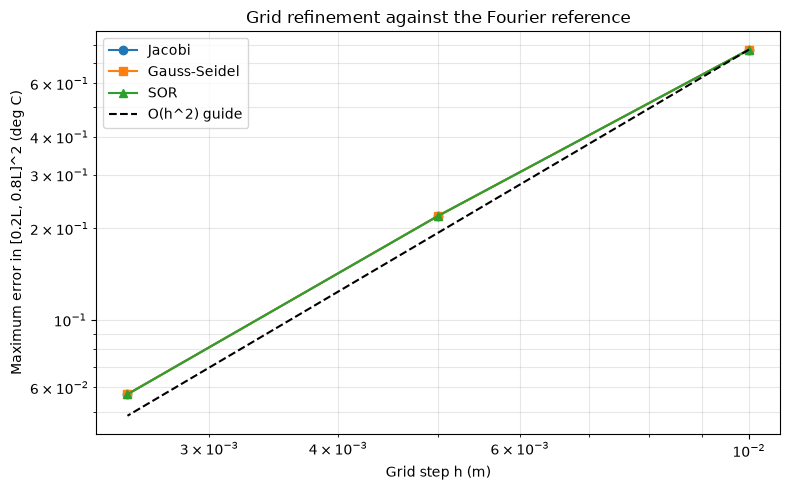

In [ ]:
def fourier_reference(x, y):
    x, y = np.asarray(x) / length, np.asarray(y) / length
    u = np.zeros(np.broadcast_shapes(x.shape, y.shape))
    # The largest sinh argument is 199*pi, safely below float64 overflow.
    for k in range(1, 200, 2):
        a = k * np.pi
        from_left = left * np.sin(a * y) * np.sinh(a * (1 - x)) / np.sinh(a)
        from_right = right * np.sin(a * y) * np.sinh(a * x) / np.sinh(a)
        from_bottom = bottom * np.sin(a * x) * np.sinh(a * (1 - y)) / np.sinh(a)
        from_top = top * np.sin(a * x) * np.sinh(a * y) / np.sinh(a)
        u += 4 / a * (from_left + from_right + from_bottom + from_top)
    return u

grid_sizes = [10, 20, 40]
grid_errors = {method: [] for method in methods}
print("Method          Intervals   Maximum error (deg C)   Order")
for n in grid_sizes:
    axis = np.linspace(0, length, n + 1)
    indices = np.arange(n // 5, 4 * n // 5 + 1)
    x, y = np.meshgrid(axis[indices], axis[indices])
    exact = fourier_reference(x, y)
    for method in methods:
        if n == intervals:
            u = solutions[method]
        else:
            u, _ = solve_heat(n, method, optimal_omega(n))
        error = np.max(np.abs(u[np.ix_(indices, indices)] - exact)) * temperature_scale
        previous = grid_errors[method]
        order = np.log2(previous[-1] / error) if previous and error > 0 else None
        previous.append(error)
        order_text = f"{order:.3f}" if order is not None else "n/a"
        print(f"{method:14s} {n:8d}      {error:.6e}              {order_text}")

fig, ax = plt.subplots(figsize=(8, 5))
steps = length / np.array(grid_sizes)
for method, marker in zip(methods, ("o", "s", "^")):
    ax.loglog(steps, grid_errors[method], marker=marker, label=method)
ax.loglog(steps, grid_errors["SOR"][0] * (steps / steps[0])**2, "k--", label="O(h^2) guide")
ax.set_xlabel("Grid step h (m)")
ax.set_ylabel("Maximum error in [0.2L, 0.8L]^2 (deg C)")
ax.set_title("Grid refinement against the Fourier reference")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

### Влияние параметра релаксации

Перебираем несколько $\omega\in[1,2)$ и добавляем теоретический оптимум.
При слишком большом параметре число итераций снова растёт.
Минимум числа итераций для конечного допуска может немного отличаться
от минимума асимптотического спектрального радиуса.

Theoretical optimum: 1.72945382
Best sampled omega: 1.72945382; iterations: 80


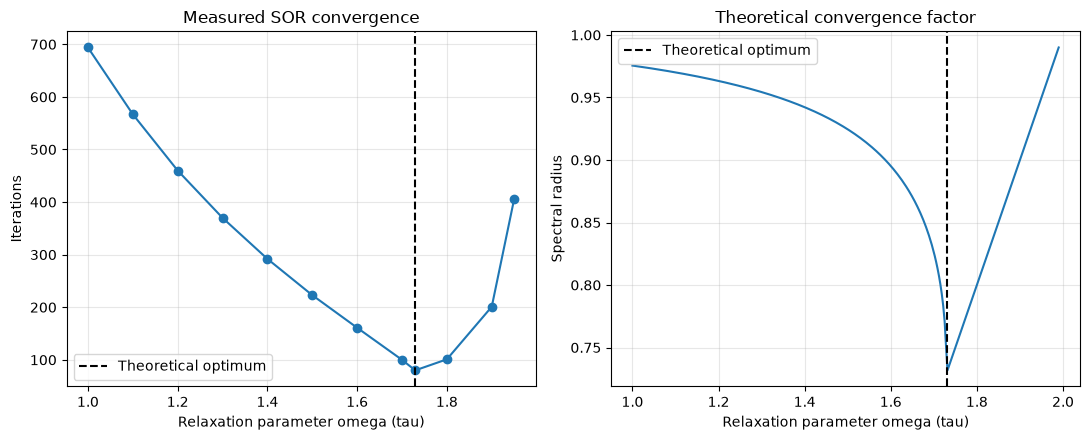

In [ ]:
omega_values = sorted([1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 1.95, omega])
iteration_counts = []
for value in omega_values:
    _, history = solve_heat(intervals, "SOR", value)
    count = len(history) - 1
    iteration_counts.append(count)
best_index = np.argmin(iteration_counts)
print(f"Theoretical optimum: {omega:.8f}")
print(f"Best sampled omega: {omega_values[best_index]:.8f}; "
      f"iterations: {iteration_counts[best_index]}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(omega_values, iteration_counts, "o-")
axes[0].set_ylabel("Iterations")
axes[0].set_title("Measured SOR convergence")
dense_omega = np.linspace(1, 1.99, 300)
axes[1].plot(dense_omega, [spectral_radius(intervals, "SOR", value) for value in dense_omega])
axes[1].set_ylabel("Spectral radius")
axes[1].set_title("Theoretical convergence factor")
for ax in axes:
    ax.axvline(omega, color="black", linestyle="--", label="Theoretical optimum")
    ax.set_xlabel("Relaxation parameter omega (tau)")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. Проверка реализации

Проверим границы, сравним небольшую разностную систему с независимой
сборкой матрицы, проверим SOR при параметре 1 и отказ при малом лимите.
Готовый решатель NumPy используется только для контрольной проверки.

In [ ]:
# Assemble the small discrete problem independently of the iteration routines.
n = 4
initial = initial_temperature(n)
matrix = np.zeros(((n - 1)**2, (n - 1)**2))
rhs = np.zeros((n - 1)**2)
for j in range(1, n):
    for i in range(1, n):
        row = (j - 1) * (n - 1) + i - 1
        matrix[row, row] = 4
        for jj, ii in ((j, i - 1), (j, i + 1), (j - 1, i), (j + 1, i)):
            if 0 < jj < n and 0 < ii < n:
                column = (jj - 1) * (n - 1) + ii - 1
                matrix[row, column] = -1
            else:
                rhs[row] += initial[jj, ii]
expected = np.linalg.solve(matrix, rhs).reshape(n - 1, n - 1)
for method in methods:
    u, history = solve_heat(n, method, optimal_omega(n), tol=1e-12)
    np.testing.assert_allclose(u[1:-1, 1:-1], expected, atol=1e-10)
    np.testing.assert_array_equal(u[[0, -1], :], initial[[0, -1], :])
    np.testing.assert_array_equal(u[:, [0, -1]], initial[:, [0, -1]])
    assert history[-1] <= 1e-12
seidel_u, _ = solve_heat(6, "Gauss-Seidel")
sor_u, _ = solve_heat(6, "SOR", omega=1.0)
np.testing.assert_allclose(seidel_u, sor_u, atol=1e-12)
np.testing.assert_allclose(fourier_reference(length / 2, length / 2), (left + right + top + bottom) / 4)
assert grid_errors["SOR"][-1] < grid_errors["SOR"][0]
try:
    solve_heat(10, "Jacobi", limit=1)
except RuntimeError:
    pass
else:
    raise AssertionError("An unfinished iteration must be reported as a failure.")
print("All heat-equation checks passed.")

All heat-equation checks passed.
